# 01 — Logistic regression on real clinical data: who develops diabetes?

**Dataset.** Pima Indians Diabetes (NIDDK, 1988): 768 women aged 21+, 8 measurements taken at a check-up, and whether
they were diagnosed with diabetes within 5 years. Small, messy, and a classic — which is exactly why it is good
practice: it has a trap that most online tutorials fall into.

**What you will learn — as an engineer, not just as a student of the formula**
- Look at the data *before* any model, and find what is wrong with it.
- Split first, then preprocess, so nothing from the test set leaks into training.
- Always beat a dumb baseline before celebrating.
- Write logistic regression yourself (sigmoid, loss, gradient, training loop), then check it against scikit-learn.
- Discover *by experiment* why feature scaling matters for gradient descent.
- Read coefficients as odds ratios — and know when not to trust them.
- Turn probabilities into decisions: thresholds, sensitivity, PPV.

**Time:** ~2–2.5 h. You can stop after any part.

**Legend**

| | |
|---|---|
| 📖 | read — the idea, short |
| 🔮 | predict before you run — write a guess and a confidence tag `[1]` guessing / `[2]` fairly sure / `[3]` certain |
| ✍️ | your code — usually 1–5 lines, `???` marks what to write |
| 🧪 | explore — open-ended, no check, no right answer; write one line about what you saw |
| 🛠️ | engineer's habit — something you will do on every project from now on |

Hints are folded in `▶ Hint` blocks. Open them after ~10 minutes stuck, not before.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlj.datasets import load_pima

rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (6, 3.5)

def check(cond, msg):
    print(("✅ " if cond else "❌ ") + msg)

## Part 1 — Meet the data (20 min)

🛠️ **Habit: never fit a model on data you have not looked at.** Five minutes of `describe()` and histograms catch
problems that no amount of tuning will fix.

In [2]:
df = load_pima()
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00
Glucose,768.0,120.895,31.973,0.000,99.000,117.000,140.250,199.00
BloodPressure,768.0,69.105,19.356,0.000,62.000,72.000,80.000,122.00
SkinThickness,768.0,20.536,15.952,0.000,0.000,23.000,32.000,99.00
Insulin,768.0,79.799,115.244,0.000,0.000,30.500,127.250,846.00
BMI,768.0,31.993,7.884,0.000,27.300,32.000,36.600,67.10
DiabetesPedigreeFunction,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42
Age,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00
Outcome,768.0,0.349,0.477,0.000,0.000,0.000,1.000,1.00


🔮 Look at the `min` column above. Which values are physiologically impossible for a living person?

> Prediction:

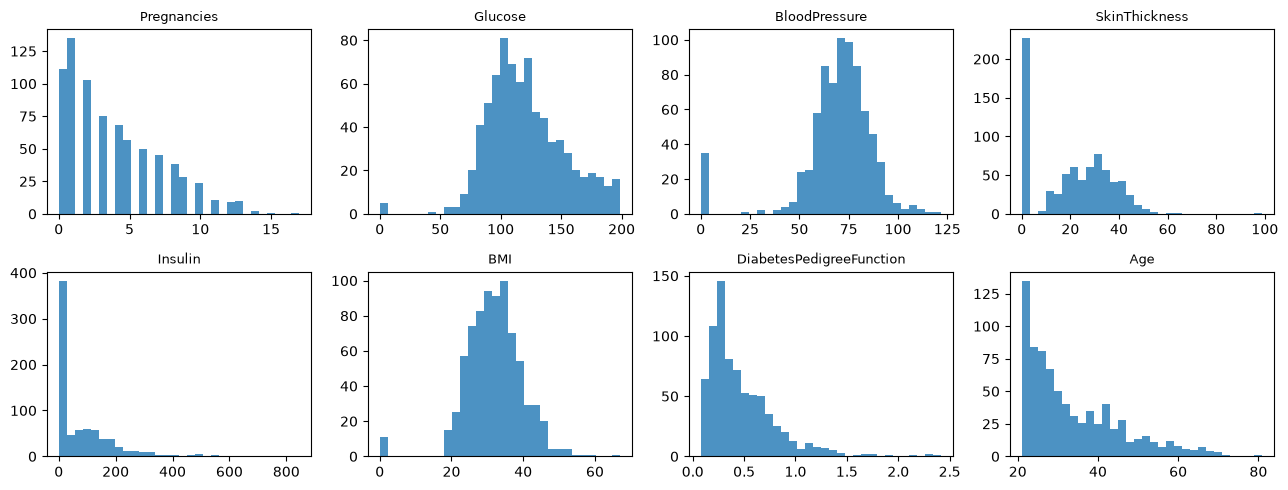

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5))
for ax, col in zip(axes.flat, df.columns[:-1]):
    ax.hist(df[col], bins=30, color="tab:blue", alpha=0.8)
    ax.set_title(col, fontsize=9)
plt.tight_layout(); plt.show()

See those spikes at 0? A blood pressure of 0 means a dead patient, not a healthy one. In this dataset **0 was used to
mean "not measured"**. Pregnancies = 0 is fine (it is a real count), the others are not.

✍️ Count the zeros in each column, then replace the impossible zeros by `NaN` in a copy of the dataframe.

In [5]:
impossible_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zeros = (df == 0).sum()
print(zeros)
df_clean = df.copy()
df_clean[impossible_zero] = df_clean[impossible_zero].replace(0, np.nan)

print("\nfraction missing:\n", df_clean.isna().mean().round(3))
check(df_clean["Insulin"].isna().sum() == 374 and df_clean["Pregnancies"].isna().sum() == 0, "zeros replaced in the right columns")

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

fraction missing:
 Pregnancies                 0.000
Glucose                     0.007
BloodPressure               0.046
SkinThickness               0.296
Insulin                     0.487
BMI                         0.014
DiabetesPedigreeFunction    0.000
Age                         0.000
Outcome                     0.000
dtype: float64
✅ zeros replaced in the right columns


Almost half of `Insulin` is missing. A tutorial that leaves the zeros in is telling the model that "insulin = 0" is a
real low value. It is not — it is "the doctor did not order the test".

🧪 **Is missingness informative?** Compare the diabetes rate for patients whose insulin was measured vs not. If they
differ, the *fact of being measured* carries information (doctors order tests when they suspect something). This
matters a lot in clinical data, and has a name: *informative missingness*.

In [6]:
print(df_clean.groupby(df_clean["Insulin"].isna())["Outcome"].agg(["mean", "size"]))

          mean  size
Insulin             
False    0.330   394
True     0.369   374


> What I see:

📖 **Prevalence** = fraction of positives. Here about 35 %. Write it down — every number later must be read against
it. (In the real population it is much lower: this cohort was selected for being at high risk.)

## Part 2 — Split first, preprocess second (10 min)

🛠️ **Habit: split before anything that learns from data — including imputation and scaling.** If you compute the
median of `Insulin` on the full dataset, a bit of the test set leaks into training. With 768 rows it barely matters;
on a real project it is the classic way to get a result nobody can reproduce.

We use 60 % train, 20 % validation (to make choices), 20 % test (looked at **once**, at the very end). `stratify`
keeps the prevalence identical in the three parts.

In [7]:
from sklearn.model_selection import train_test_split

features = [c for c in df_clean.columns if c != "Outcome"]
trainval, test = train_test_split(df_clean, test_size=0.2, stratify=df_clean["Outcome"], random_state=0)
train, val = train_test_split(trainval, test_size=0.25, stratify=trainval["Outcome"], random_state=0)
print(len(train), len(val), len(test), "| prevalence:", [round(d["Outcome"].mean(), 3) for d in (train, val, test)])

460 154 154 | prevalence: [np.float64(0.348), np.float64(0.351), np.float64(0.351)]


✍️ Impute the missing values with the **training** medians, and apply the same medians to val and test.

In [8]:
medians = train[features].median()
def impute(d):
    return d[features].fillna(medians)

X_tr, X_va, X_te = impute(train), impute(val), impute(test)
y_tr, y_va, y_te = train["Outcome"].to_numpy(), val["Outcome"].to_numpy(), test["Outcome"].to_numpy()
check(not X_tr.isna().any().any() and not X_te.isna().any().any(), "no NaN left")
check(np.isclose(medians["Insulin"], train["Insulin"].median()), "medians come from train")

✅ no NaN left
✅ medians come from train


## Part 3 — Baselines: the numbers to beat (10 min)

🔮 A "model" that always answers *no diabetes*. What accuracy does it get on validation?

> Prediction:

In [9]:
acc_majority = np.mean(y_va == 0)
print(f"always-no accuracy: {acc_majority:.3f}")

always-no accuracy: 0.649


65 % accuracy while detecting **zero** patients. Keep this in mind when someone shows you "75 % accuracy".

A smarter baseline: one rule, `Glucose > t`. Doctors already do roughly this (fasting glucose thresholds).

✍️ Find the threshold `t` that maximises accuracy on **train**, then report its accuracy on **val**.

best threshold 142 mg/dL -> val accuracy 0.740


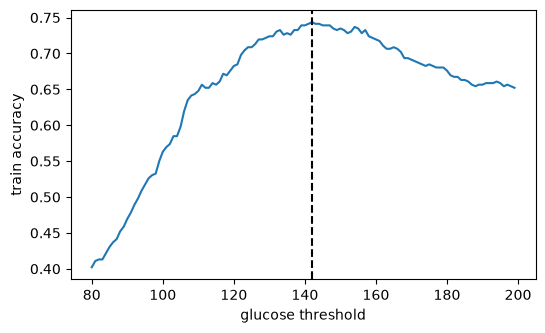

In [10]:
ts = np.arange(80, 200)
train_acc = [np.mean((X_tr["Glucose"].to_numpy() > t) == y_tr) for t in ts]
t_best = ts[int(np.argmax(train_acc))]
acc_rule = np.mean((X_va["Glucose"].to_numpy() > t_best) == y_va)
print(f"best threshold {t_best} mg/dL -> val accuracy {acc_rule:.3f}")
plt.plot(ts, train_acc); plt.axvline(t_best, ls="--", c="k"); plt.xlabel("glucose threshold"); plt.ylabel("train accuracy"); plt.show()

That is the real bar. A model with 8 features that does not clearly beat one glucose threshold is not worth its
complexity.

## Part 4 — Logistic regression, one feature, from scratch (40 min)

📖 **The model.** For one feature: `p(y=1 | x) = σ(w·x + b)` with `σ(z) = 1 / (1 + e^{-z})`. The number `z = w·x + b`
is called the **logit** (log-odds): `z = log(p / (1 − p))`.

📖 **The loss.** Each patient is a coin flip with probability `p`. The likelihood of what we observed is
`∏ p_i^{y_i} (1 − p_i)^{1 − y_i}`. Take `−log` and average: the **binary cross-entropy**

`L = −(1/n) Σ [ y_i log p_i + (1 − y_i) log(1 − p_i) ]`.

You will compare it with other losses in notebook 02. For now: it is "how surprised the model is by the truth".

✍️ Write the four building blocks. Derive the gradient on paper first: with `p = σ(z)`, what is `∂L/∂z_i`? (It is
surprisingly simple.)

<details><summary>▶ Hint (gradient)</summary>

`σ'(z) = σ(z)(1 − σ(z))`. Chain rule on one term: `∂L_i/∂z_i = p_i − y_i`. Then `z = Xw` gives `∂L/∂w = Xᵀ(p − y)/n`.
</details>

In [11]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def predict_proba(X, w):
    """X: (n, d) with a column of ones for the bias, w: (d,) -> p: (n,)"""
    return sigmoid(X @ w)

def bce(X, y, w, eps=1e-12):
    p = predict_proba(X, w)
    return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

def bce_grad(X, y, w):
    return X.T @ (predict_proba(X, w) - y) / len(y)

🛠️ **Habit: check every hand-written gradient numerically.** Wrong gradients often still "train" — just badly — and you
will never notice by looking at the loss curve. A central difference is 5 lines and saves hours.

In [12]:
def numerical_grad(f, w, eps=1e-6):
    g = np.zeros_like(w)
    for i in range(len(w)):
        e = np.zeros_like(w); e[i] = eps
        g[i] = (f(w + e) - f(w - e)) / (2 * eps)
    return g

add_bias = lambda A: np.column_stack([np.ones(len(A)), A])
Xg_tr = add_bias(X_tr[["Glucose"]].to_numpy() / 100)      # glucose in units of 100 mg/dL (we'll come back to this)
w_test = np.array([0.3, -0.7])
num = numerical_grad(lambda w: bce(Xg_tr, y_tr, w), w_test)
check(np.allclose(bce_grad(Xg_tr, y_tr, w_test), num, atol=1e-6), f"gradient matches numerical {num.round(5)}")
check(np.isclose(bce(Xg_tr, y_tr, np.zeros(2)), np.log(2)), "loss at w = 0 is log 2 (p = 0.5 for everyone)")

✅ gradient matches numerical [ 0.01798 -0.05914]
✅ loss at w = 0 is log 2 (p = 0.5 for everyone)


✍️ The training loop: plain gradient descent. Keep the loss history — you will want to look at it.

w =

 [-5.288  3.698] | final loss 0.534


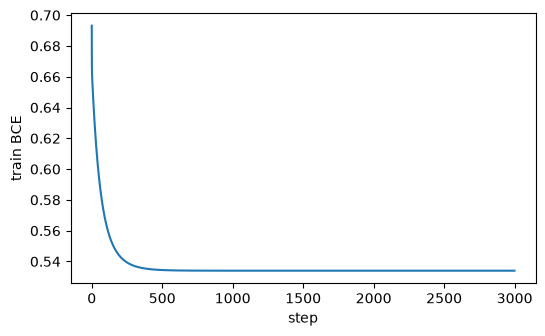

In [13]:
def fit_gd(X, y, lr=0.1, n_steps=2000):
    w = np.zeros(X.shape[1])
    history = []
    for _ in range(n_steps):
        history.append(bce(X, y, w))
        w = w - lr * bce_grad(X, y, w)
    return w, np.array(history)

w1, hist = fit_gd(Xg_tr, y_tr, lr=1.0, n_steps=3000)
print("w =", w1.round(3), "| final loss", hist[-1].round(4))
plt.plot(hist); plt.xlabel("step"); plt.ylabel("train BCE"); plt.show()

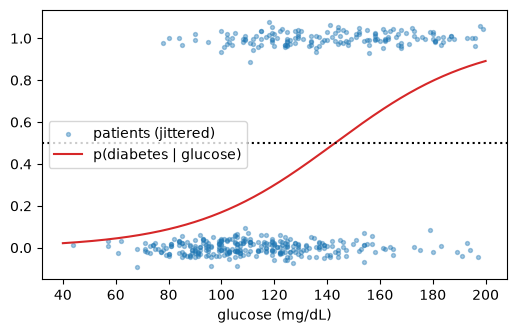

glucose where p = 0.5: 143 mg/dL  (compare with the threshold rule: 142)


In [14]:
g = np.linspace(40, 200, 200)
plt.scatter(X_tr["Glucose"], y_tr + rng.normal(0, 0.03, len(y_tr)), s=8, alpha=0.4, label="patients (jittered)")
plt.plot(g, predict_proba(add_bias(g / 100), w1), c="tab:red", label="p(diabetes | glucose)")
plt.axhline(0.5, ls=":", c="k"); plt.xlabel("glucose (mg/dL)"); plt.legend(); plt.show()
print(f"glucose where p = 0.5: {-w1[0] / w1[1] * 100:.0f} mg/dL  (compare with the threshold rule: {t_best})")

🧪 **Explore — why did I divide glucose by 100?** Re-run `fit_gd` on the raw glucose (`X_tr[["Glucose"]]` without
`/ 100`) with a few learning rates: `1.0`, `0.01`, `1e-4`. Plot the loss curves. Then try the *standardised* glucose
`(x − mean) / std` with `lr = 1.0`. (Overflow warnings from `np.exp` mean the weights blew up: that *is* the result.)

What you should end up understanding: gradient descent uses **one** learning rate for all weights. When one input is
~120 and the bias input is 1, the loss surface is a very long thin valley — a step size that is safe in the steep
direction is tiny in the flat one. Standardising makes the valley round. (Notebook 03 shows this in pictures.)

/tmp/ipykernel_1032/1764574488.py:2: RuntimeWarning: overflow encountered in exp
  return 1.0 / (1.0 + np.exp(-z))


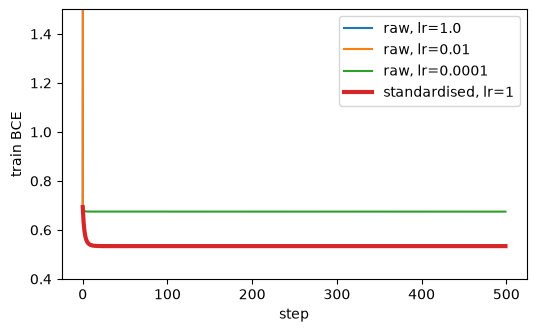

In [15]:
Xraw = add_bias(X_tr[["Glucose"]].to_numpy())
Xstd = add_bias(((X_tr["Glucose"] - X_tr["Glucose"].mean()) / X_tr["Glucose"].std()).to_numpy())
for lr in [1.0, 1e-2, 1e-4]:
    _, h = fit_gd(Xraw, y_tr, lr=lr, n_steps=500)
    plt.plot(h, label=f"raw, lr={lr}")
_, h = fit_gd(Xstd, y_tr, lr=1.0, n_steps=500)
plt.plot(h, label="standardised, lr=1", lw=3)
plt.ylim(0.4, 1.5); plt.legend(); plt.xlabel("step"); plt.ylabel("train BCE"); plt.show()

> What I see:

## Part 5 — All eight features (30 min)

✍️ Standardise with the **train** mean and std (same rule as imputation), add the bias column, fit.

In [16]:
mu, sd = X_tr.mean(), X_tr.std()
standardise = lambda X: add_bias(((X - mu) / sd).to_numpy())
A_tr, A_va, A_te = standardise(X_tr), standardise(X_va), standardise(X_te)

w_all, hist_all = fit_gd(A_tr, y_tr, lr=0.5, n_steps=3000)
acc = lambda A, y, w, t=0.5: np.mean((predict_proba(A, w) > t) == y)
print(f"train acc {acc(A_tr, y_tr, w_all):.3f} | val acc {acc(A_va, y_va, w_all):.3f} | glucose rule {acc_rule:.3f}")

train acc 0.767 | val acc 0.753 | glucose rule 0.740


🛠️ **Habit: check your from-scratch model against a library.** If they disagree, one of you is wrong — usually you,
sometimes a default setting you did not know about (sklearn regularises by default!).

In [17]:
from sklearn.linear_model import LogisticRegression

sk = LogisticRegression(C=np.inf, max_iter=5000).fit(A_tr[:, 1:], y_tr)   # C = inf: no regularisation
w_sk = np.r_[sk.intercept_, sk.coef_[0]]
print(pd.DataFrame({"mine": w_all, "sklearn": w_sk}, index=["bias"] + features).round(3))
check(np.allclose(w_all, w_sk, atol=1e-2), "same weights as sklearn (no regularisation)")

                           mine  sklearn
bias                     -0.883   -0.883
Pregnancies               0.510    0.511
Glucose                   0.959    0.959
BloodPressure            -0.005   -0.004
SkinThickness             0.167    0.167
Insulin                   0.040    0.040
BMI                       0.610    0.609
DiabetesPedigreeFunction  0.222    0.222
Age                       0.131    0.130
✅ same weights as sklearn (no regularisation)


📖 **Reading the weights.** Because inputs are standardised, `w_j` is the change in log-odds for **+1 standard
deviation** of feature `j`, all others held fixed. `exp(w_j)` is the **odds ratio**: `1.5` means "odds × 1.5".

✍️ Plot the odds ratios (log scale) per feature.

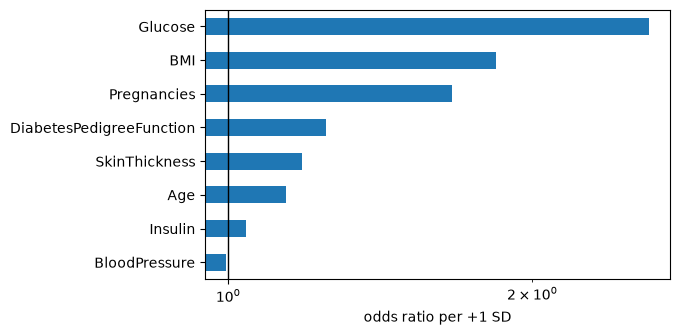

In [18]:
odds = pd.Series(np.exp(w_all[1:]), index=features).sort_values()
odds.plot.barh(logx=True); plt.axvline(1, c="k", lw=1); plt.xlabel("odds ratio per +1 SD"); plt.show()

🔮 Before the next cell: if you **remove Glucose** and refit, what happens to the weights of `Insulin` and `BMI`?

> Prediction:

🧪 **Explore.** Refit without `Glucose` (drop column index 2 in `A_tr`, i.e. `np.delete(A_tr, 2, axis=1)`) and compare
the weights and the val accuracy. Then think about what this means for a sentence like "insulin barely matters for
diabetes, its coefficient is small". Correlated features share the credit; a coefficient is *conditional on the
others* and says nothing causal.

In [19]:
w_noglu, _ = fit_gd(np.delete(A_tr, 2, axis=1), y_tr, lr=0.5, n_steps=3000)
names_noglu = ["bias"] + [f for f in features if f != "Glucose"]
print(pd.DataFrame({"with glucose": pd.Series(w_all, ["bias"] + features),
                    "without": pd.Series(w_noglu, names_noglu)}).round(2))
print(f"val acc without glucose: {acc(np.delete(A_va, 2, axis=1), y_va, w_noglu):.3f}")
print("corr(Glucose, Insulin) on train:", X_tr["Glucose"].corr(X_tr["Insulin"]).round(2))

                          with glucose  without
Age                               0.13     0.27
BMI                               0.61     0.65
BloodPressure                    -0.00     0.07
DiabetesPedigreeFunction          0.22     0.26
Glucose                           0.96      NaN
Insulin                           0.04     0.38
Pregnancies                       0.51     0.45
SkinThickness                     0.17     0.16
bias                             -0.88    -0.79
val acc without glucose: 0.688
corr(Glucose, Insulin) on train: 0.41


> What I see:

## Part 6 — From probabilities to decisions (25 min)

The model outputs a probability. A clinic needs a yes/no: *refer this patient for a glucose tolerance test or not*.
The threshold 0.5 is a convention, not a law.

📖 Four counts: TP, FP, TN, FN. From them:
- **sensitivity** (recall) = TP / (TP + FN): of the sick, how many we catch;
- **specificity** = TN / (TN + FP): of the healthy, how many we leave alone;
- **PPV** (precision) = TP / (TP + FP): of those we flag, how many are really sick.

✍️ Write `rates(y, p, t)` and plot the three curves against the threshold, on validation.

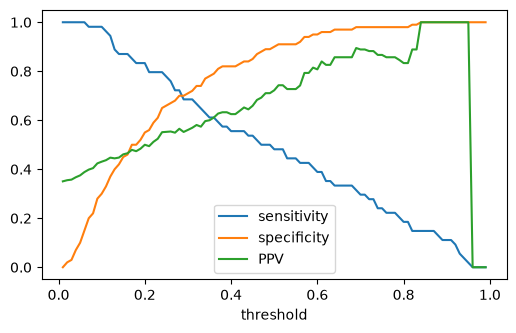

In [20]:
def rates(y, p, t):
    pred = p > t
    tp, fp = np.sum(pred & (y == 1)), np.sum(pred & (y == 0))
    fn, tn = np.sum(~pred & (y == 1)), np.sum(~pred & (y == 0))
    return tp / (tp + fn), tn / (tn + fp), tp / max(tp + fp, 1)

p_va = predict_proba(A_va, w_all)
thr = np.linspace(0.01, 0.99, 99)
R = np.array([rates(y_va, p_va, t) for t in thr])
for k, name in enumerate(["sensitivity", "specificity", "PPV"]):
    plt.plot(thr, R[:, k], label=name)
plt.xlabel("threshold"); plt.legend(); plt.show()

val AUROC: 0.793   (glucose alone: 0.802)


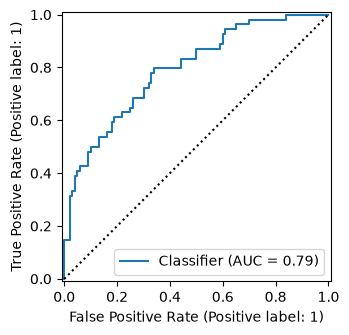

In [21]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
print(f"val AUROC: {roc_auc_score(y_va, p_va):.3f}   (glucose alone: {roc_auc_score(y_va, X_va['Glucose']):.3f})")
RocCurveDisplay.from_predictions(y_va, p_va); plt.plot([0, 1], [0, 1], "k:"); plt.show()

Look closely: on validation, the 8-feature model does **not** beat glucose alone in AUROC. Before concluding anything,
remember the validation set has 154 patients (54 diabetics). The uncertainty on an AUROC at that size is roughly
±0.07, so 0.79 vs 0.80 is noise. 🛠️ **Habit: never compare two numbers without a sense of their error bar.**

🧪 *Optional:* bootstrap it — resample the 154 val patients with replacement 1000 times, recompute both AUROCs each
time, and look at the distribution of the difference.

📖 **AUROC** = probability that a random diabetic patient gets a higher score than a random non-diabetic one. It does
not depend on any threshold — which is both its strength and why it is not enough to deploy anything.

🧪 **Explore — a screening scenario.** A screening programme wants to miss at most 10 % of future diabetics
(sensitivity ≥ 0.9). Pick the threshold on **validation**, then — once — compute sensitivity, specificity and PPV on
**test**. How many healthy women get a needless test for every diabetic found?

In [22]:
ok = thr[R[:, 0] >= 0.9]
t_screen = ok.max()
sens, spec, ppv = rates(y_te, predict_proba(A_te, w_all), t_screen)
print(f"threshold {t_screen:.2f} -> test sensitivity {sens:.2f}, specificity {spec:.2f}, PPV {ppv:.2f}")
print(f"needless tests per diabetic found: {(1 - ppv) / ppv:.2f}")

threshold 0.12 -> test sensitivity 0.98, specificity 0.50, PPV 0.51


needless tests per diabetic found: 0.94


> What I see:

🛠️ **Habit: the test set is touched once.** If you now go back and change the threshold because the test number looks
bad, the test set has become a second validation set and its number means nothing.

Things this notebook did **not** check, that a reviewer would ask about: the confidence interval on these numbers
(test has only 154 patients — try a bootstrap), calibration (is `p = 0.3` really 30 %?), and whether a model trained on
this high-risk cohort transfers to the general population (prevalence shift changes PPV). Notebook `04-practice/07`
covers these.

## Debrief → `learning/LOG.md`

Write, without looking back:
1. What was wrong with the raw data, and what would a model have learned from it?
2. BCE in terms of `p` and `y`; its gradient with respect to the logits; why the loss at `w = 0` is `log 2`.
3. In one sentence each: why scale features for gradient descent; why fit the scaler on train only.
4. Why a coefficient of a correlated feature cannot be read as its "importance".
5. **Still shaky:** every ✍️ cell that took you more than two tries, and every 🔮 tagged `[2]`/`[3]` that was wrong.